# Sentiment Analysis — Merged Project

Reproduction of **Xinya Liao (2024), *Sentiment Analysis Based on Machine Learning Models***  
plus the extensions from the team notebooks:

| Source | What we keep |
|---|---|
| Colleague notebook | Paper-faithful splits, 4 article models, MLP, DistilBERT, McNemar, controlled phrases |
| `paper.ipynb` | EDA, negation-aware preprocessing option, feature-representation ablations |
| Shared layer | One data loader, one metrics registry, one results table |

**Pipeline**

1. Load SST-2 / IMDB (paper protocol, optional `FAST_MODE`)
2. EDA
3. Preprocessing (article pipeline + optional negation-preserving variant)
4. Main TF-IDF → reproduce KNN / RF / NB / LR
5. Optional feature ablations (bigrams, BoW, char n-grams)
6. Contribution A: MLP on TF-IDF
7. Contribution B: DistilBERT fine-tune
8. Global comparison, confusion matrices, McNemar–Holm


## 0. Install (first run only)


In [1]:
# Use %pip so packages land in THIS notebook kernel (not another Python).
# Trainer / TrainingArguments require accelerate>=1.1.0.
%pip -q install "accelerate>=1.1.0"
# Optional full stack (first run / Colab):
# %pip -q install datasets "transformers[torch]" "accelerate>=1.1.0" nltk scikit-learn pandas matplotlib seaborn scipy


Note: you may need to restart the kernel to use updated packages.


## 1. Imports and configuration


In [2]:
import re
import time
import random
import warnings
import math
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import torch

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
from datasets import load_dataset, Dataset
from scipy.stats import binomtest


def holm_correction(p_values):
    """Holm step-down adjusted p-values (same idea as statsmodels multipletests method='holm')."""
    p = np.asarray(p_values, dtype=float)
    n = len(p)
    order = np.argsort(p)
    adjusted = np.empty(n)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (n - rank) * p[idx])
        adjusted[idx] = min(running, 1.0)
    return adjusted

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.feature_extraction import DictVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from sklearn.model_selection import train_test_split

from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    DataCollatorWithPadding, Trainer, TrainingArguments, set_seed,
)

for resource in ["punkt", "punkt_tab", "stopwords"]:
    nltk.download(resource, quiet=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
set_seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

# FAST_MODE=True → smaller subsets for quick local runs (same protocol, fewer rows)
FAST_MODE = True
MAX_TRAIN = 8_000 if FAST_MODE else 50_000
MAX_SST_TEST = 2_000 if FAST_MODE else 17_349
MAX_IMDB_TEST = 2_000 if FAST_MODE else 10_000
RUN_FEATURE_ABLATION = True   # set False to skip bigrams / BoW / char n-grams
RUN_DISTILBERT = True         # set False if no GPU / no transformers run wanted

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
print(f"FAST_MODE={FAST_MODE} | train={MAX_TRAIN} | sst_test={MAX_SST_TEST} | imdb_test={MAX_IMDB_TEST}")
if DEVICE == "cpu" and RUN_DISTILBERT:
    print("Note: DistilBERT on CPU is slow. Prefer a GPU, or set RUN_DISTILBERT = False.")


Device: cuda
FAST_MODE=True | train=8000 | sst_test=2000 | imdb_test=2000


## 2. Data loading (paper-faithful protocol)

Liao (2024) uses **67 349** labelled SST-2 sentences: **50 000** train + **17 349** held-out test  
(random shuffle of the official train split). We also keep the official SST-2 validation set (872)  
and a **10 000**-row sample of the IMDB test set for cross-domain evaluation.

With `FAST_MODE=True`, those sizes are subsampled but the *same* sampling logic is used.


In [3]:
sst = load_dataset("stanfordnlp/sst2", split="train").to_pandas()[["sentence", "label"]]
sst = sst.sample(frac=1, random_state=SEED).reset_index(drop=True)

n_needed = MAX_TRAIN + MAX_SST_TEST
if len(sst) < n_needed:
    raise ValueError(f"SST-2 train has {len(sst)} rows, need at least {n_needed}.")

train_df = sst.iloc[:MAX_TRAIN].copy().reset_index(drop=True)
test_df = sst.iloc[MAX_TRAIN:MAX_TRAIN + MAX_SST_TEST].copy().reset_index(drop=True)

sst_val = load_dataset("stanfordnlp/sst2", split="validation").to_pandas()[["sentence", "label"]]

imdb = load_dataset("stanfordnlp/imdb", split="test").to_pandas()[["text", "label"]]
imdb = imdb.sample(n=min(MAX_IMDB_TEST, len(imdb)), random_state=SEED).reset_index(drop=True)

# Unified column name for EDA
train_df = train_df.rename(columns={"sentence": "text"})
test_df = test_df.rename(columns={"sentence": "text"})
sst_val = sst_val.rename(columns={"sentence": "text"})

print(f"SST-2 train : {len(train_df):,}  (pos {train_df.label.mean():.3f})")
print(f"SST-2 test  : {len(test_df):,}  (pos {test_df.label.mean():.3f})")
print(f"SST-2 val.  : {len(sst_val):,}  (pos {sst_val.label.mean():.3f})")
print(f"IMDB test   : {len(imdb):,}  (pos {imdb.label.mean():.3f})")


SST-2 train : 8,000  (pos 0.566)
SST-2 test  : 2,000  (pos 0.557)
SST-2 val.  : 872  (pos 0.509)
IMDB test   : 2,000  (pos 0.480)


## 3. Exploratory Data Analysis 

Class balance, text length, and most frequent words on the loaded splits.



===== SST-2 train =====
sentiment
Positive    4531
Negative    3469
       n_words
count   8000.0
mean       9.6
std        8.1
min        1.0
25%        3.0
50%        7.0
75%       14.0
max       50.0

===== SST-2 test =====
sentiment
Positive    1115
Negative     885
       n_words
count   2000.0
mean       9.1
std        8.1
min        1.0
25%        3.0
50%        6.0
75%       13.0
max       47.0

===== IMDB test =====
sentiment
Negative    1040
Positive     960
       n_words
count   2000.0
mean     225.7
std      165.9
min       17.0
25%      126.8
50%      169.5
75%      272.2
max     1090.0


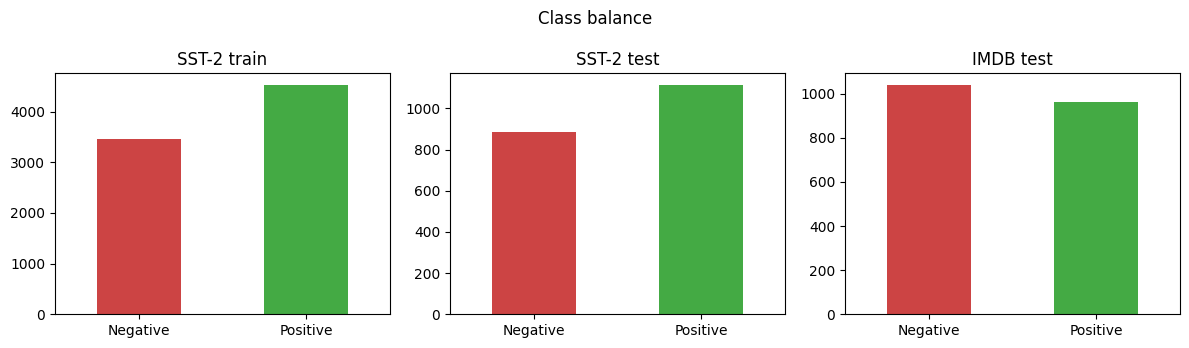

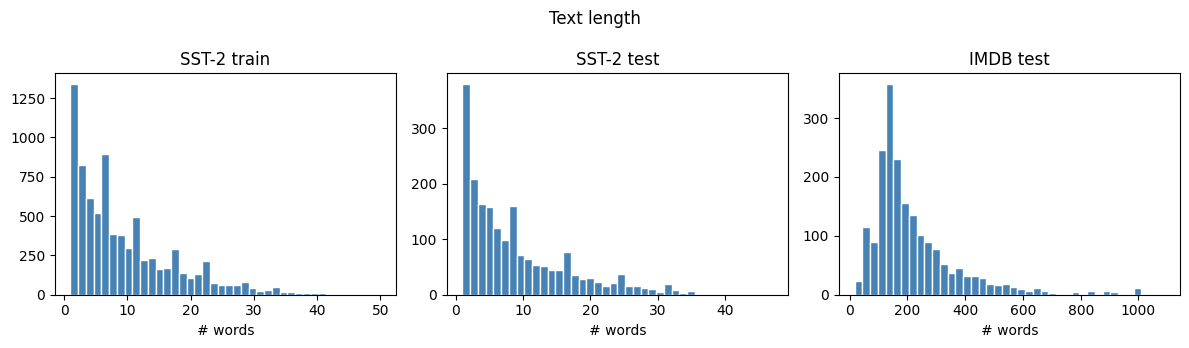

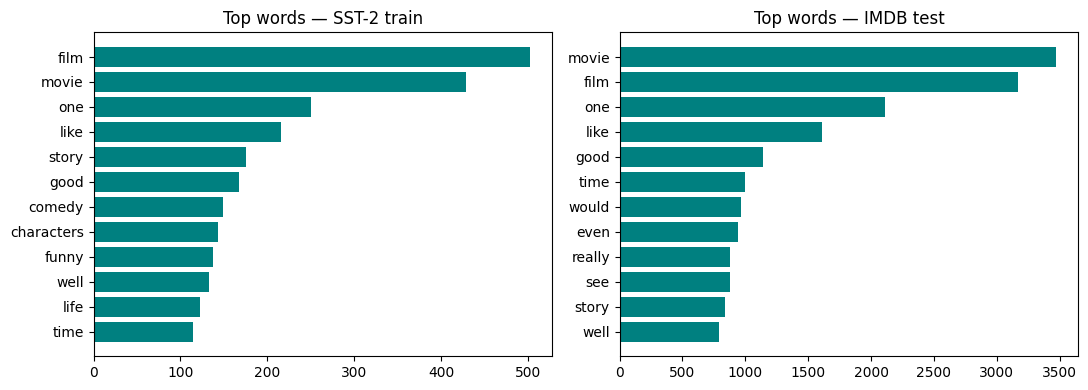

In [4]:
label_names = {0: "Negative", 1: "Positive"}
stop_eda = set(stopwords.words("english"))

eda_frames = {
    "SST-2 train": train_df.assign(split="train", dataset="SST-2"),
    "SST-2 test": test_df.assign(split="test", dataset="SST-2"),
    "IMDB test": imdb.assign(split="test", dataset="IMDB"),
}
for name, df in eda_frames.items():
    df = df.copy()
    df["sentiment"] = df["label"].map(label_names)
    df["n_words"] = df["text"].astype(str).str.split().str.len()
    eda_frames[name] = df
    print(f"\n===== {name} =====")
    print(df["sentiment"].value_counts().to_string())
    print(df[["n_words"]].describe().round(1).to_string())

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (name, df) in zip(axes, eda_frames.items()):
    df["sentiment"].value_counts().reindex(["Negative", "Positive"]).plot(
        kind="bar", ax=ax, color=["#c44", "#4a4"]
    )
    ax.set_title(name)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
fig.suptitle("Class balance")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (name, df) in zip(axes, eda_frames.items()):
    ax.hist(df["n_words"], bins=40, color="steelblue", edgecolor="white")
    ax.set_title(name)
    ax.set_xlabel("# words")
fig.suptitle("Text length")
fig.tight_layout()
plt.show()

def top_words(texts, n=12):
    words = []
    for t in texts:
        toks = re.findall(r"[a-z]+", str(t).lower())
        words.extend(w for w in toks if w not in stop_eda and len(w) > 2)
    return Counter(words).most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, texts) in zip(axes, [("SST-2 train", train_df["text"]), ("IMDB test", imdb["text"])]):
    labels, counts = zip(*top_words(texts))
    ax.barh(list(labels)[::-1], list(counts)[::-1], color="teal")
    ax.set_title(f"Top words — {name}")
fig.tight_layout()
plt.show()


## 4. Preprocessing

**Article pipeline** (`preprocess_article`) — used for the main reproduction / MLP:  
lowercase → tokenize → drop non-alpha tokens → remove **all** NLTK stopwords → Porter stem.

**Negation-aware pipeline** (`preprocess_negation`) — optional variant from `paper.ipynb`:  
same steps, but negation cues (`not`, `no`, `never`, …) are **kept**.

> Warning: the article pipeline removes `not` / `n't`, which can hurt negation cases. DistilBERT uses **raw** text.


In [5]:
STOP_ALL = set(stopwords.words("english"))
NEGATIONS = {
    "no", "not", "nor", "none", "nothing", "never", "neither", "nobody",
    "isnt", "arent", "wasnt", "werent", "dont", "doesnt", "didnt",
    "cant", "cannot", "couldnt", "wont", "wouldnt", "shouldnt",
    "havent", "hasnt", "hadnt", "hardly", "barely", "scarcely",
}
STOP_KEEP_NEG = STOP_ALL - NEGATIONS
stemmer = PorterStemmer()

def _tokenize_clean(text):
    text = re.sub(r"<br\s*/?>", " ", str(text).lower())
    return [t for t in word_tokenize(text) if t.isalpha()]

def preprocess_article(text):
    tokens = [t for t in _tokenize_clean(text) if t not in STOP_ALL]
    return " ".join(stemmer.stem(t) for t in tokens)

def preprocess_negation(text):
    tokens = [t for t in _tokenize_clean(text) if t not in STOP_KEEP_NEG]
    return " ".join(stemmer.stem(t) for t in tokens)

examples = ["I am not happy with this movie.", "This film was hardly good."]
for ex in examples:
    print("RAW     :", ex)
    print("article :", preprocess_article(ex))
    print("negation:", preprocess_negation(ex))
    print()

# Main columns used everywhere below = article pipeline
for df in (train_df, test_df, sst_val, imdb):
    df["clean"] = df["text"].apply(preprocess_article)
    df["clean_neg"] = df["text"].apply(preprocess_negation)

display(train_df[["text", "clean", "clean_neg", "label"]].head(3))


RAW     : I am not happy with this movie.
article : happi movi
negation: not happi movi

RAW     : This film was hardly good.
article : film hardli good
negation: film hardli good



,text,clean,clean_neg,label
0,with outtakes in which most of the characters ...,outtak charact forget line utter uhhh better w...,outtak charact forget line utter uhhh better w...,0
1,enigma is well-made,enigma,enigma,1
2,is ) so stoked to make an important film about...,stoke make import film human infidel happenst ...,stoke make import film human infidel happenst ...,0


## 5. Main TF-IDF + evaluation helpers

Vectorizer is fit on **SST-2 train only**, then applied to SST-2 test, SST-2 val, and IMDB.


In [6]:
tfidf = TfidfVectorizer()
X_train = tfidf.fit_transform(train_df["clean"])
y_train = train_df["label"].astype(int).values

X_by_set = {
    "SST-2":      tfidf.transform(test_df["clean"]),
    "SST-2 val.": tfidf.transform(sst_val["clean"]),
    "IMDB":       tfidf.transform(imdb["clean"]),
}
Y = {
    "SST-2":      test_df["label"].astype(int).values,
    "SST-2 val.": sst_val["label"].astype(int).values,
    "IMDB":       imdb["label"].astype(int).values,
}
RAW = {
    "SST-2":      test_df["text"].tolist(),
    "SST-2 val.": sst_val["text"].tolist(),
    "IMDB":       imdb["text"].str.replace(r"<br\s*/?>", " ", regex=True).tolist(),
}

preds = {}      # (model, dataset) -> predictions
timings = {}    # model -> train seconds
fitted = {}     # model name -> fitted estimator (sklearn)

def metrics(y, pred):
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="weighted", zero_division=0)
    return {"Accuracy": accuracy_score(y, pred), "Precision": p, "Recall": r, "F1-score": f}

def register_sklearn(name, model, feature_sets=None):
    feature_sets = feature_sets or X_by_set
    fitted[name] = model
    for ds, X in feature_sets.items():
        preds[(name, ds)] = model.predict(X)

def results_table(names, datasets=None):
    datasets = datasets or list(Y)
    rows = []
    for n in names:
        for ds in datasets:
            rows.append({"Model": n, "Dataset": ds, **metrics(Y[ds], preds[(n, ds)])})
    return pd.DataFrame(rows)

print("TF-IDF train:", X_train.shape)
for k, v in X_by_set.items():
    print(f"TF-IDF {k}:", v.shape)


TF-IDF train: (8000, 6366)
TF-IDF SST-2: (2000, 6366)
TF-IDF SST-2 val.: (872, 6366)
TF-IDF IMDB: (2000, 6366)


## 6. Reproduce the 4 article models

Hyper-parameters aligned with the colleague notebook / paper:

- KNN: `n_neighbors=5`
- Random Forest: `n_estimators=8`, bootstrap
- Multinomial NB: defaults
- Logistic Regression: `max_iter=1000`


In [7]:
models_article = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(
        n_estimators=8, bootstrap=True, random_state=SEED, n_jobs=-1
    ),
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
}

for name, model in models_article.items():
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    timings[name] = time.perf_counter() - t0
    register_sklearn(name, model)
    print(f"{name}: trained in {timings[name]:.1f}s")

ARTICLE_MODELS = list(models_article)
results_reproduction = results_table(ARTICLE_MODELS)
display(results_reproduction.round(3))


KNN: trained in 0.0s
Random Forest: trained in 0.1s
Naive Bayes: trained in 0.0s
Logistic Regression: trained in 0.0s


,Model,Dataset,Accuracy,Precision,Recall,F1-score
0,KNN,SST-2,0.677,0.677,0.677,0.677
1,KNN,SST-2 val.,0.538,0.538,0.538,0.537
2,KNN,IMDB,0.495,0.497,0.495,0.495
3,Random Forest,SST-2,0.790,0.790,0.790,0.789
4,Random Forest,SST-2 val.,0.731,0.731,0.731,0.730
5,Random Forest,IMDB,0.625,0.627,0.625,0.619
6,Naive Bayes,SST-2,0.814,0.822,0.814,0.810
7,Naive Bayes,SST-2 val.,0.735,0.763,0.735,0.727
8,Naive Bayes,IMDB,0.792,0.798,0.792,0.791
9,Logistic Regression,SST-2,0.804,0.806,0.804,0.802


### 6.1 Comparison with published Table 1 (SST-2 & IMDB)


In [8]:
article_results = pd.DataFrame([
    ["KNN", "SST-2", 0.88, 0.88, 0.88, 0.87],
    ["KNN", "IMDB", 0.50, 0.54, 0.50, 0.35],
    ["Random Forest", "SST-2", 0.89, 0.89, 0.89, 0.89],
    ["Random Forest", "IMDB", 0.67, 0.68, 0.67, 0.67],
    ["Naive Bayes", "SST-2", 0.87, 0.87, 0.87, 0.87],
    ["Naive Bayes", "IMDB", 0.80, 0.80, 0.80, 0.80],
    ["Logistic Regression", "SST-2", 0.88, 0.88, 0.88, 0.88],
    ["Logistic Regression", "IMDB", 0.81, 0.81, 0.81, 0.81],
], columns=["Model", "Dataset", "Accuracy", "Precision", "Recall", "F1-score"])

comparison_article = results_reproduction.merge(
    article_results, on=["Model", "Dataset"], suffixes=(" (ours)", " (paper)")
)
print("Ours vs paper (only rows present in the paper table):")
display(comparison_article.round(3))


Ours vs paper (only rows present in the paper table):


,Model,Dataset,Accuracy (ours),Precision (ours),Recall (ours),F1-score (ours),Accuracy (paper),Precision (paper),Recall (paper),F1-score (paper)
0,KNN,SST-2,0.677,0.677,0.677,0.677,0.88,0.88,0.88,0.87
1,KNN,IMDB,0.495,0.497,0.495,0.495,0.50,0.54,0.50,0.35
2,Random Forest,SST-2,0.790,0.790,0.790,0.789,0.89,0.89,0.89,0.89
3,Random Forest,IMDB,0.625,0.627,0.625,0.619,0.67,0.68,0.67,0.67
4,Naive Bayes,SST-2,0.814,0.822,0.814,0.810,0.87,0.87,0.87,0.87
5,Naive Bayes,IMDB,0.792,0.798,0.792,0.791,0.80,0.80,0.80,0.80
6,Logistic Regression,SST-2,0.804,0.806,0.804,0.802,0.88,0.88,0.88,0.88
7,Logistic Regression,IMDB,0.798,0.799,0.798,0.798,0.81,0.81,0.81,0.81


### 6.2 Diagnostic: share of positive predictions

A low F1 with ~0.50 accuracy can mean the model almost always predicts one class (classic KNN issue on IMDB in the paper).


In [9]:
dist = pd.DataFrame({ds: {n: preds[(n, ds)].mean() for n in ARTICLE_MODELS} for ds in Y})
dist.loc["(true positive rate)"] = [Y[ds].mean() for ds in Y]
display(dist.round(3))


,SST-2,SST-2 val.,IMDB
KNN,0.562,0.531,0.535
Random Forest,0.590,0.519,0.377
Naive Bayes,0.654,0.675,0.546
Logistic Regression,0.624,0.627,0.503
(true positive rate),0.558,0.509,0.480


## 7. Feature-representation ablation (from `paper.ipynb`)

Same 4 classifiers, but different features fit on SST-2 train only:

| Representation | How |
|---|---|
| TF-IDF (main) | already done above |
| TF-IDF + bigrams | `TfidfVectorizer(ngram_range=(1,2))` |
| Bag of Words | binary `CountVectorizer` |
| Char n-grams (3–5) | binary char `CountVectorizer` |

Skipped when `RUN_FEATURE_ABLATION = False`.



=== TF-IDF + bigrams | train shape (8000, 10725) ===

=== Bag of Words | train shape (8000, 4098) ===

=== Char n-grams (3-5) | train shape (8000, 30000) ===

Ablation — Accuracy pivot (SST-2 / IMDB):


Dataset                                 SST-2   IMDB
Representation     Model                            
TF-IDF + bigrams   KNN                  0.702  0.513
                   Random Forest        0.773  0.675
                   Naive Bayes          0.816  0.794
                   Logistic Regression  0.806  0.796
Bag of Words       KNN                  0.676  0.620
                   Random Forest        0.782  0.686
                   Naive Bayes          0.801  0.784
                   Logistic Regression  0.804  0.786
Char n-grams (3-5) KNN                  0.682  0.556
                   Random Forest        0.772  0.550
                   Naive Bayes          0.810  0.714
                   Logistic Regression  0.833  0.750
TF-IDF (main)      KNN                  0.677  0.495
                   Random Forest        0.790  0.625
                   Naive Bayes          0.814  0.792
                   Logistic Regression  0.804  0.798

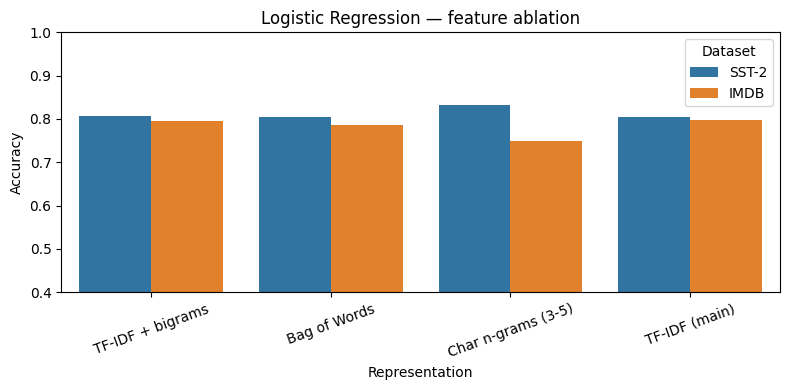

In [10]:
ablation_rows = []

if RUN_FEATURE_ABLATION:
    feature_builders = {
        "TF-IDF + bigrams": TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=30_000),
        "Bag of Words": CountVectorizer(binary=True, min_df=2, max_features=30_000),
        "Char n-grams (3-5)": CountVectorizer(
            analyzer="char", ngram_range=(3, 5), min_df=2, max_features=30_000
        ),
    }
    # Char n-grams: use lowercased raw text; others: article-cleaned text
    train_text_word = train_df["clean"].tolist()
    test_text_word = {
        "SST-2": test_df["clean"].tolist(),
        "SST-2 val.": sst_val["clean"].tolist(),
        "IMDB": imdb["clean"].tolist(),
    }
    train_text_char = train_df["text"].str.lower().tolist()
    test_text_char = {
        "SST-2": test_df["text"].str.lower().tolist(),
        "SST-2 val.": sst_val["text"].str.lower().tolist(),
        "IMDB": imdb["text"].str.lower().str.replace(r"<br\s*/?>", " ", regex=True).tolist(),
    }

    ablation_models = {
        "KNN": lambda: KNeighborsClassifier(n_neighbors=5),
        "Random Forest": lambda: RandomForestClassifier(
            n_estimators=8, bootstrap=True, random_state=SEED, n_jobs=-1
        ),
        "Naive Bayes": lambda: MultinomialNB(),
        "Logistic Regression": lambda: LogisticRegression(max_iter=1000, random_state=SEED),
    }

    for feat_name, vectorizer in feature_builders.items():
        use_char = feat_name.startswith("Char")
        tr = train_text_char if use_char else train_text_word
        te = test_text_char if use_char else test_text_word
        Xtr = vectorizer.fit_transform(tr)
        Xte = {ds: vectorizer.transform(te[ds]) for ds in Y}
        print(f"\n=== {feat_name} | train shape {Xtr.shape} ===")
        for model_name, factory in ablation_models.items():
            clf = factory()
            clf.fit(Xtr, y_train)
            for ds in Y:
                pred = clf.predict(Xte[ds])
                ablation_rows.append({
                    "Representation": feat_name,
                    "Model": model_name,
                    "Dataset": ds,
                    **metrics(Y[ds], pred),
                })

    # Add main TF-IDF results into the ablation table for a single view
    for model_name in ARTICLE_MODELS:
        for ds in Y:
            ablation_rows.append({
                "Representation": "TF-IDF (main)",
                "Model": model_name,
                "Dataset": ds,
                **metrics(Y[ds], preds[(model_name, ds)]),
            })

    ablation_df = pd.DataFrame(ablation_rows)
    print("\nAblation — Accuracy pivot (SST-2 / IMDB):")
    pivot = ablation_df[ablation_df.Dataset.isin(["SST-2", "IMDB"])].pivot_table(
        index=["Representation", "Model"], columns="Dataset", values="Accuracy", sort=False
    )
    display(pivot.round(3))

    # Bar plot: Logistic Regression across representations
    lr_ab = ablation_df[(ablation_df.Model == "Logistic Regression") & (ablation_df.Dataset.isin(["SST-2", "IMDB"]))]
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(data=lr_ab, x="Representation", y="Accuracy", hue="Dataset", ax=ax)
    ax.set_ylim(0.4, 1.0)
    ax.set_title("Logistic Regression — feature ablation")
    ax.tick_params(axis="x", rotation=20)
    fig.tight_layout()
    plt.show()
else:
    ablation_df = pd.DataFrame()
    print("Feature ablation skipped (RUN_FEATURE_ABLATION=False).")


### 7.1 Optional: negation-aware preprocess vs article preprocess (same TF-IDF + LR)

Quick check of whether keeping negation words helps on IMDB / controlled cases.


In [11]:
tfidf_neg = TfidfVectorizer()
X_train_neg = tfidf_neg.fit_transform(train_df["clean_neg"])
X_neg = {
    "SST-2": tfidf_neg.transform(test_df["clean_neg"]),
    "SST-2 val.": tfidf_neg.transform(sst_val["clean_neg"]),
    "IMDB": tfidf_neg.transform(imdb["clean_neg"]),
}
lr_neg = LogisticRegression(max_iter=1000, random_state=SEED)
lr_neg.fit(X_train_neg, y_train)

neg_rows = []
for ds in Y:
    pred_art = preds[("Logistic Regression", ds)]
    pred_neg = lr_neg.predict(X_neg[ds])
    neg_rows.append({"Preprocess": "article (drop not)", "Dataset": ds, **metrics(Y[ds], pred_art)})
    neg_rows.append({"Preprocess": "keep negations", "Dataset": ds, **metrics(Y[ds], pred_neg)})
display(pd.DataFrame(neg_rows).round(3))


,Preprocess,Dataset,Accuracy,Precision,Recall,F1-score
0,article (drop not),SST-2,0.804,0.806,0.804,0.802
1,keep negations,SST-2,0.807,0.810,0.807,0.804
2,article (drop not),SST-2 val.,0.763,0.777,0.763,0.759
3,keep negations,SST-2 val.,0.767,0.779,0.767,0.764
4,article (drop not),IMDB,0.798,0.799,0.798,0.798
5,keep negations,IMDB,0.802,0.803,0.802,0.802


## 8. Contribution A — MLP on TF-IDF

Same TF-IDF matrix as the article models.  
1 hidden layer (256 ReLU), early stopping.


In [12]:
mlp = MLPClassifier(
    hidden_layer_sizes=(256,),
    activation="relu",
    alpha=1e-4,
    batch_size=256,
    learning_rate_init=1e-3,
    max_iter=30,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=3,
    random_state=SEED,
)

t0 = time.perf_counter()
mlp.fit(X_train, y_train)
timings["MLP (TF-IDF)"] = time.perf_counter() - t0
register_sklearn("MLP (TF-IDF)", mlp)

print(f"MLP trained in {timings['MLP (TF-IDF)']:.1f}s, {mlp.n_iter_} epochs")
print(f"Best internal validation score: {mlp.best_validation_score_:.3f}")
display(results_table(["MLP (TF-IDF)"]).round(3))


MLP trained in 15.9s, 10 epochs
Best internal validation score: 0.801


,Model,Dataset,Accuracy,Precision,Recall,F1-score
0,MLP (TF-IDF),SST-2,0.810,0.809,0.810,0.809
1,MLP (TF-IDF),SST-2 val.,0.759,0.766,0.759,0.757
2,MLP (TF-IDF),IMDB,0.790,0.791,0.790,0.791


## 9. Contribution B — DistilBERT fine-tune

`distilbert-base-uncased` fine-tuned on the **same SST-2 train texts** (raw, not stemmed).  
Truncation: 128 for SST-2, 256 for IMDB. Skipped when `RUN_DISTILBERT=False`.


In [13]:
if RUN_DISTILBERT:
    # Ensure accelerate is installed into THIS kernel, then refresh transformers' cached check
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "accelerate>=1.1.0"])
    from transformers.utils.import_utils import is_accelerate_available
    is_accelerate_available.cache_clear()

    MODEL_NAME = "distilbert-base-uncased"
    MAX_LEN = {"SST-2": 128, "SST-2 val.": 128, "IMDB": 256}
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

    def to_hf(texts, labels, max_len):
        ds = Dataset.from_dict({"text": list(texts), "labels": [int(l) for l in labels]})
        return ds.map(
            lambda b: tokenizer(b["text"], truncation=True, max_length=max_len),
            batched=True,
            remove_columns=["text"],
        )

    train_ds = to_hf(train_df["text"], train_df["label"], 128)
    model_bert = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

    training_args = TrainingArguments(
        output_dir="./distilbert_sst2",
        num_train_epochs=2,
        per_device_train_batch_size=16 if DEVICE == "cpu" else 32,
        per_device_eval_batch_size=64 if DEVICE == "cpu" else 128,
        learning_rate=2e-5,
        weight_decay=0.01,
        warmup_steps=100 if FAST_MODE else 200,
        fp16=(DEVICE == "cuda"),
        logging_steps=50 if FAST_MODE else 200,
        save_strategy="no",
        report_to="none",
        seed=SEED,
    )

    trainer = Trainer(
        model=model_bert,
        args=training_args,
        train_dataset=train_ds,
        data_collator=DataCollatorWithPadding(tokenizer),
    )

    t0 = time.perf_counter()
    trainer.train()
    timings["DistilBERT"] = time.perf_counter() - t0
    print(f"DistilBERT trained in {timings['DistilBERT']:.0f}s")

    for ds in Y:
        eval_ds = to_hf(RAW[ds], Y[ds], MAX_LEN[ds])
        logits = trainer.predict(eval_ds).predictions
        preds[("DistilBERT", ds)] = logits.argmax(axis=-1)

    display(results_table(["DistilBERT"]).round(3))
else:
    trainer = None
    print("DistilBERT skipped (RUN_DISTILBERT=False).")


Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.686698
100,0.529444
150,0.359824
200,0.289164
250,0.289096
300,0.225552
350,0.202141
400,0.213266
450,0.186288
500,0.190130


DistilBERT trained in 49s


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

,Model,Dataset,Accuracy,Precision,Recall,F1-score
0,DistilBERT,SST-2,0.900,0.900,0.900,0.900
1,DistilBERT,SST-2 val.,0.888,0.888,0.888,0.888
2,DistilBERT,IMDB,0.850,0.851,0.850,0.850


## 10. Global comparison


Accuracy


Dataset,SST-2,SST-2 val.,IMDB
Model,,,
KNN,0.677,0.538,0.495
Random Forest,0.790,0.731,0.625
Naive Bayes,0.814,0.735,0.792
Logistic Regression,0.804,0.763,0.798
MLP (TF-IDF),0.810,0.759,0.790
DistilBERT,0.900,0.888,0.850


F1-score (weighted)


Dataset,SST-2,SST-2 val.,IMDB
Model,,,
KNN,0.677,0.537,0.495
Random Forest,0.789,0.730,0.619
Naive Bayes,0.810,0.727,0.791
Logistic Regression,0.802,0.759,0.798
MLP (TF-IDF),0.809,0.757,0.791
DistilBERT,0.900,0.888,0.850


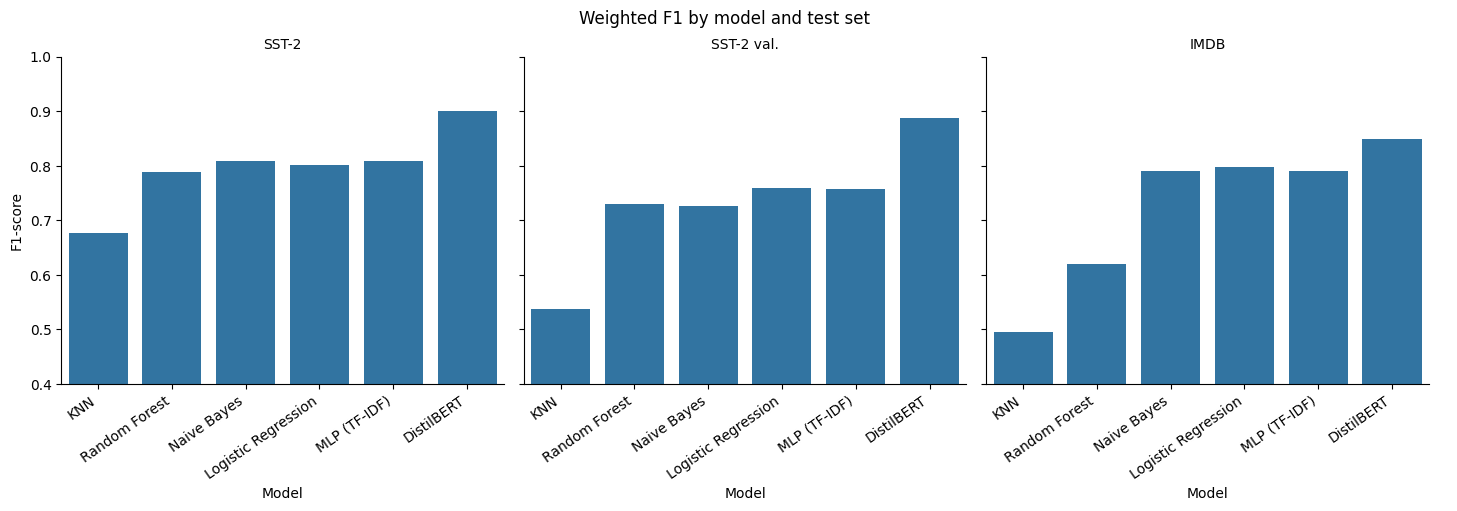

Saved results_merged_all.csv


In [14]:
ALL_MODELS = ARTICLE_MODELS + ["MLP (TF-IDF)"]
if ("DistilBERT", "SST-2") in preds:
    ALL_MODELS = ALL_MODELS + ["DistilBERT"]

results_all = results_table(ALL_MODELS)
print("Accuracy")
display(results_all.pivot_table(index="Model", columns="Dataset", values="Accuracy", sort=False)[list(Y)].round(3))
print("F1-score (weighted)")
display(results_all.pivot_table(index="Model", columns="Dataset", values="F1-score", sort=False)[list(Y)].round(3))

g = sns.catplot(
    data=results_all, x="Model", y="F1-score", col="Dataset", col_order=list(Y),
    kind="bar", errorbar=None, height=4.2, aspect=1.15,
)
g.set(ylim=(0.4, 1.0))
g.set_xticklabels(rotation=35, ha="right")
g.set_titles("{col_name}")
g.figure.suptitle("Weighted F1 by model and test set", y=1.03)
plt.show()

results_all.to_csv("results_merged_all.csv", index=False)
print("Saved results_merged_all.csv")


### 10.1 Confusion matrices


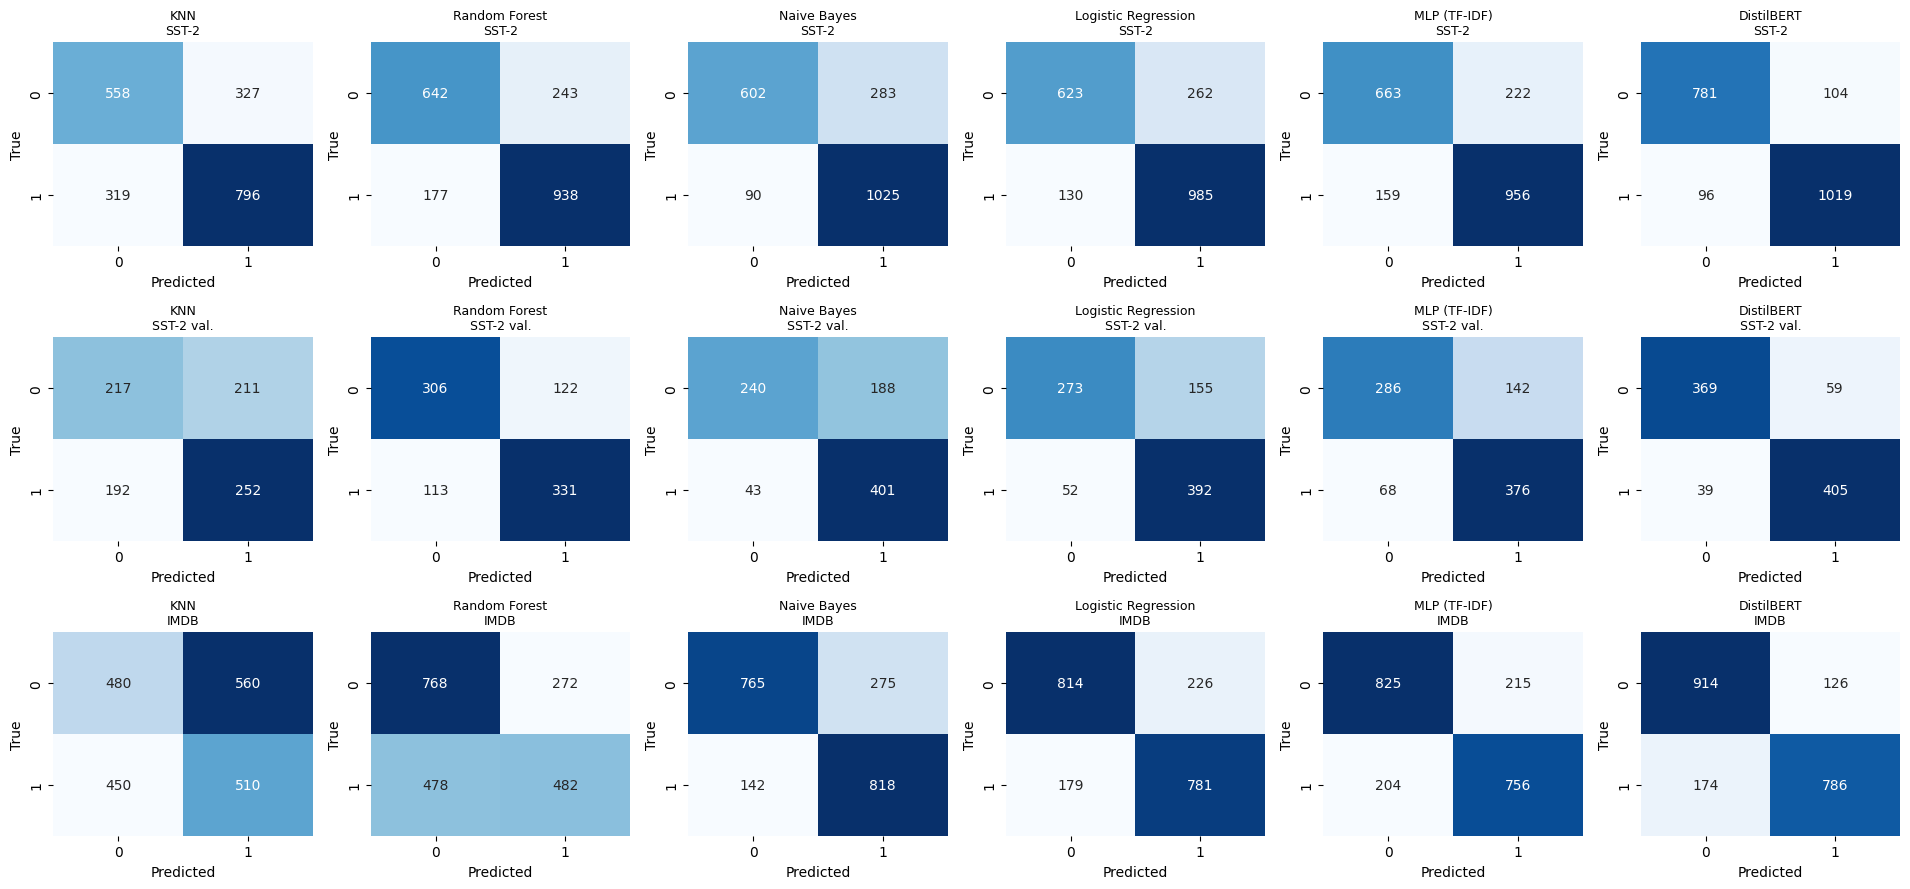

In [15]:
fig, axes = plt.subplots(len(Y), len(ALL_MODELS), figsize=(3.2 * len(ALL_MODELS), 3.0 * len(Y)))
if len(ALL_MODELS) == 1:
    axes = np.array(axes).reshape(len(Y), 1)
for i, ds in enumerate(Y):
    for j, name in enumerate(ALL_MODELS):
        cm = confusion_matrix(Y[ds], preds[(name, ds)], labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i, j])
        axes[i, j].set_title(f"{name}\n{ds}", fontsize=9)
        axes[i, j].set_xlabel("Predicted")
        axes[i, j].set_ylabel("True")
fig.tight_layout()
plt.show()


### 10.2 McNemar exact test + Holm correction

Compare MLP / DistilBERT against Logistic Regression (and each other) on the **same examples**.


In [16]:
def mcnemar_exact(y, pred_1, pred_2):
    ok1, ok2 = (pred_1 == y), (pred_2 == y)
    only1 = int((ok1 & ~ok2).sum())
    only2 = int((~ok1 & ok2).sum())
    n = only1 + only2
    p = binomtest(only1, n, 0.5).pvalue if n > 0 else 1.0
    return only1, only2, p

PAIRS = [("MLP (TF-IDF)", "Logistic Regression")]
if ("DistilBERT", "SST-2") in preds:
    PAIRS += [
        ("DistilBERT", "Logistic Regression"),
        ("DistilBERT", "MLP (TF-IDF)"),
    ]

rows = []
for m1, m2 in PAIRS:
    for ds in Y:
        o1, o2, p = mcnemar_exact(Y[ds], preds[(m1, ds)], preds[(m2, ds)])
        rows.append({
            "Model 1": m1, "Model 2": m2, "Dataset": ds,
            "Only M1 correct": o1, "Only M2 correct": o2, "p-value": p,
        })

results_mcnemar = pd.DataFrame(rows)
results_mcnemar["p Holm"] = holm_correction(results_mcnemar["p-value"])
results_mcnemar["Significant (Holm 5%)"] = results_mcnemar["p Holm"] < 0.05
display(results_mcnemar.round(4))


,Model 1,Model 2,Dataset,Only M1 correct,Only M2 correct,p-value,p Holm,Significant (Holm 5%)
0,MLP (TF-IDF),Logistic Regression,SST-2,95,84,0.4549,0.9122,False
1,MLP (TF-IDF),Logistic Regression,SST-2 val.,50,53,0.8439,0.9122,False
2,MLP (TF-IDF),Logistic Regression,IMDB,73,87,0.3041,0.9122,False
3,DistilBERT,Logistic Regression,SST-2,300,108,0.0000,0.0000,True
4,DistilBERT,Logistic Regression,SST-2 val.,154,45,0.0000,0.0000,True
5,DistilBERT,Logistic Regression,IMDB,243,138,0.0000,0.0000,True
6,DistilBERT,MLP (TF-IDF),SST-2,291,110,0.0000,0.0000,True
7,DistilBERT,MLP (TF-IDF),SST-2 val.,162,50,0.0000,0.0000,True
8,DistilBERT,MLP (TF-IDF),IMDB,267,148,0.0000,0.0000,True


## 11. Controlled phrases (illustrative)

Tiny qualitative check — not a substitute for the held-out sets. Useful to see negation / emoji behaviour.


In [17]:
controlled_examples = [
    "I am happy",
    "I am not happy",
    "This movie is good",
    "This movie is not good",
    "I don't like it",
    "The film was bad",
    "The film was not bad",
    "I really love this movie",
    "I really hate this movie",
]

def proba_sklearn(model, texts, preprocess_fn=preprocess_article, vectorizer=tfidf):
    return model.predict_proba(vectorizer.transform([preprocess_fn(t) for t in texts]))[:, 1]

cols = {
    "Logistic Regression": proba_sklearn(fitted["Logistic Regression"], controlled_examples),
    "MLP (TF-IDF)": proba_sklearn(fitted["MLP (TF-IDF)"], controlled_examples),
    "LR (keep negations)": proba_sklearn(lr_neg, controlled_examples, preprocess_negation, tfidf_neg),
}
if trainer is not None:
    def proba_bert(texts):
        m = trainer.model
        m.eval()
        enc = tokenizer(texts, padding=True, truncation=True, max_length=128, return_tensors="pt").to(m.device)
        with torch.no_grad():
            logits = m(**enc).logits
        return torch.softmax(logits.float(), dim=-1)[:, 1].cpu().numpy()
    cols["DistilBERT"] = proba_bert(controlled_examples)

controlled = pd.DataFrame({"Text": controlled_examples, **cols}).set_index("Text")
print("P(positive) by model")
display(controlled.round(3))


P(positive) by model


,Logistic Regression,MLP (TF-IDF),LR (keep negations),DistilBERT
Text,,,,
I am happy,0.723,0.942,0.729,0.986
I am not happy,0.723,0.942,0.371,0.024
This movie is good,0.897,0.976,0.918,0.991
This movie is not good,0.897,0.976,0.600,0.025
I don't like it,0.346,0.326,0.362,0.041
The film was bad,0.070,0.015,0.073,0.024
The film was not bad,0.070,0.015,0.026,0.299
I really love this movie,0.781,0.934,0.802,0.989
I really hate this movie,0.239,0.048,0.259,0.061


## 12. Training time


,train_seconds
KNN,0.0
Random Forest,0.1
Naive Bayes,0.0
Logistic Regression,0.0
MLP (TF-IDF),15.9
DistilBERT,49.4


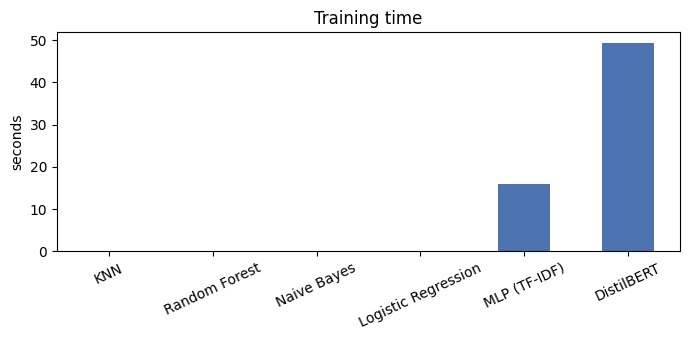

In [18]:
time_df = pd.Series(timings, name="train_seconds").round(1).to_frame()
display(time_df)
fig, ax = plt.subplots(figsize=(7, 3.5))
time_df["train_seconds"].plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_ylabel("seconds")
ax.set_title("Training time")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()


## 13. Discussion points for the report

1. Compare the 4 reproduced models to Liao’s Table 1 (absolute numbers may differ if `FAST_MODE=True`).
2. Explain the KNN IMDB collapse via the positive-prediction diagnostic.
3. Feature ablation: do bigrams / char n-grams help transfer to IMDB?
4. Negation-aware stopwords: does keeping `not` improve controlled phrases and/or IMDB?
5. MLP vs Logistic Regression on the same TF-IDF — is the gain significant (McNemar)?
6. DistilBERT vs classical models — accuracy / F1 / time trade-off.
7. Limitations: article preprocessing removes negation cues; IMDB is much longer than SST-2; FAST_MODE numbers are not paper-comparable.


## 14. Optional exports

Uncomment to save sklearn artefacts locally (or adapt paths for Colab Drive).


In [19]:
import joblib, os
os.makedirs("artifacts", exist_ok=True)
joblib.dump(tfidf, "artifacts/tfidf_article.joblib")
joblib.dump(fitted["Logistic Regression"], "artifacts/lr_article.joblib")
joblib.dump(fitted["MLP (TF-IDF)"], "artifacts/mlp_tfidf.joblib")
results_all.to_csv("artifacts/results_merged_all.csv", index=False)
if not ablation_df.empty:
    ablation_df.to_csv("artifacts/results_feature_ablation.csv", index=False)
print("Exports are commented out — uncomment when needed.")


Exports are commented out — uncomment when needed.
